# Détection des tumeurs cérébrales avec YOLOv8 🧠

**Notebook débutant : préparation → visualisation → entraînement → évaluation.**

Nous partons de ta structure `data/raw/detection/Train/Glioma/images/` et `labels/` (même principe pour `Meningioma`, `No Tumor`, `Pituitary` et `Val`).

**Classes de détection :** `0=glioma`, `1=meningioma`, `2=pituitary`. `No Tumor` est une **image négative** (annotation vide). Les annotations positives sont supposées contenir une seule pathologie, donnée par leur dossier.

**Préalable :** depuis le dossier principal du projet, installer les dépendances :

```powershell
python -m pip install -r requirements_detection.txt
```

Ne pas exécuter ce notebook avant d'avoir contrôlé la signification des étiquettes source, notamment si `No Tumor` contient des boîtes.

## Étape 0 — Définir les chemins du projet

- `ROOT` : dossier principal `BrainTumorDetectionAI`.
- `RAW` : tes images et fichiers `.txt` d'origine. **Nous ne modifions jamais RAW**.
- `PROCESSED` : nouvelle copie au format attendu par YOLO.
- `ARTIFACTS` : sauvegardes des modèles, graphiques et métriques.

Le code fonctionne si le notebook est lancé depuis `notebooks/` ou depuis la racine.

In [1]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

RAW = ROOT / "data" / "raw" / "detection"
PROCESSED = ROOT / "data" / "processed" / "detection"
ARTIFACTS = ROOT / "artifacts" / "detection"
CONFIG = ROOT / "configs" / "detection_train.yaml"

print("Projet :", ROOT)
print("Données brutes trouvées :", RAW.exists())
print("Configuration trouvée :", CONFIG.exists())

Projet : C:\Users\errak\Desktop\BrainTumorDetectionAI
Données brutes trouvées : True
Configuration trouvée : True


## Étape 1 — Vérifier les images et leurs annotations

`scan_dataset()` parcourt chaque sous-dossier `Train`, `Val` et `Test` (si présent). Pour une image `irm01.jpg`, il recherche `labels/irm01.txt` en comparant les **noms sans extension**.

- `paired` : image et annotation existent.
- `missing_label` : image sans annotation.
- `orphan_label` : annotation sans image.

Pour `No Tumor`, l'absence de `.txt` est normale : nous créerons un label vide.

In [2]:
from src.detection.dataset import scan_dataset

inventory = pd.DataFrame(scan_dataset(RAW))
if inventory.empty:
    raise ValueError("Aucune donnée reconnue. Vérifier RAW et les noms des dossiers.")

display(inventory.groupby(["split", "class_folder", "status"]).size().reset_index(name="nombre"))
print("Total fichiers inspectés :", len(inventory))

,split,class_folder,status,nombre
0,Train,Glioma,paired,1153
1,Train,Meningioma,paired,1449
2,Train,No Tumor,paired,711
3,Train,Pituitary,paired,1424
4,Val,Glioma,paired,136
5,Val,Meningioma,paired,140
6,Val,No Tumor,missing_label,2
7,Val,No Tumor,orphan_label,2
8,Val,No Tumor,paired,98
9,Val,Pituitary,paired,136


Total fichiers inspectés : 5251


## Étape 2 — Voir quelques images brutes avec leurs boîtes

Une annotation YOLO contient une ligne par boîte :

`class_id x_center y_center largeur hauteur`

Par exemple `0 0.50 0.40 0.25 0.30`. Les quatre coordonnées sont **normalisées de 0 à 1**. Pour dessiner le rectangle, on multiplie par la taille réelle de l'image :

`x_gauche = (x_centre - largeur / 2) × largeur_image`.

Cette première visualisation sert à vérifier que les rectangles correspondent vraiment aux tumeurs.

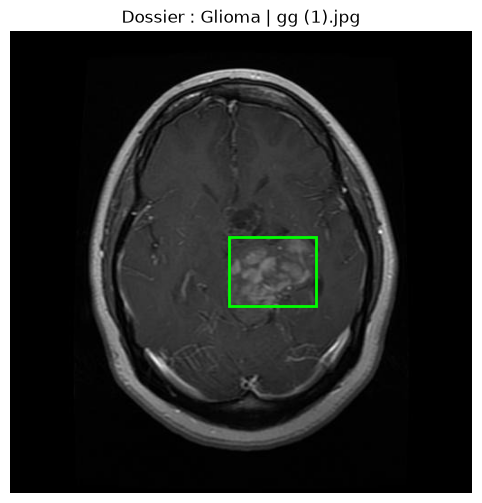

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from src.detection.validate_labels import read_yolo_label

# Prend la première image de tumeur dont le label est valide.
candidates = inventory[(inventory["status"] == "paired") & (inventory["class_folder"].str.lower() != "no tumor")]

valid_row = None
for _, row in candidates.iterrows():
    try:
        objects = read_yolo_label(row["label"])
        if objects:
            valid_row = row
            break
    except ValueError:
        continue

if valid_row is not None:
    image = Image.open(valid_row["image"]).convert("RGB")
    width, height = image.size
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(image)
    for _, x, y, w, h in objects:
        ax.add_patch(Rectangle(((x-w/2)*width, (y-h/2)*height),
                               w*width, h*height, fill=False,
                               edgecolor="lime", linewidth=2))
    ax.set_title(f"Dossier : {valid_row['class_folder']} | {Path(valid_row['image']).name}")
    ax.axis("off")
    plt.show()
else:
    print("Aucun couple image / annotation valide pour la visualisation.")

## Étape 3 — Valider les labels et organiser les splits

`prepare_dataset()` fait les opérations suivantes :

1. lit chaque fichier `.txt` avec `read_yolo_label()` ; vérifie le nombre de valeurs, l'ID entier et les coordonnées ;
2. ignore les fichiers invalides et les annotations orphelines ;
3. associe chaque boîte à la classe indiquée par le **dossier source** ;
4. garde `Val` pour la validation ; si `Test` n'existe pas, réserve **20 % de Train** au test ;
5. repère les images **strictement identiques** par SHA-256 pour empêcher qu'une copie exacte figure dans deux splits ;
6. copie les paires vers `data/processed/detection/...`, génère `data.yaml` et un rapport CSV.

⚠️ **Important :** si deux IRM différentes viennent d'un même patient, le contrôle SHA-256 ne suffit pas. Pour un vrai protocole médical, faire le partage par **patient** avant de lancer ce pipeline.

Le pipeline peut être relancé : il recrée les seuls fichiers dérivés contenus dans `data/processed/detection/`. Il ne modifie pas `data/raw`.

In [4]:
from src.detection.dataset import prepare_dataset

SOURCE_ID_TO_CLASS = {
    0: "glioma",
    1: "meningioma",
    2: "notumor",
    3: "pituitary"
}

data_yaml, report_csv = prepare_dataset(
    raw_root=RAW,
    output_root=PROCESSED,
    test_ratio=0.20,
    seed=42,
    source_id_to_class=SOURCE_ID_TO_CLASS
)


===== RÉSUMÉ (images copiées) =====
train / glioma     : 726
train / meningioma : 665
train / pituitary  : 645
train / notumor    : 388
val   / glioma     : 123
val   / meningioma : 128
val   / pituitary  : 136
val   / notumor    : 93
test  / glioma     : 196
test  / meningioma : 246
test  / pituitary  : 245
test  / notumor    : 120

Éléments ignorés : 1540
Fichier YAML : C:\Users\errak\Desktop\BrainTumorDetectionAI\data\processed\detection\data.yaml
Rapport : C:\Users\errak\Desktop\BrainTumorDetectionAI\data\processed\detection\preparation_report.csv
IDs bruts observés : {'glioma': [0, 1, 3], 'meningioma': [0, 1, 3], 'notumor': [2], 'pituitary': [1, 3]}
Correspondance source utilisée (à vérifier dans le data.yaml source) : {0: 'glioma', 1: 'meningioma', 2: 'notumor', 3: 'pituitary'}


## Étape 4 — Lire le rapport et compter les images

Le CSV contient `copied` pour les images retenues et un motif explicite pour chaque élément rejeté. **Vérifie les rejets** avant d'entraîner le modèle.

In [5]:
report = pd.read_csv(report_csv)
print("Résumé des résultats :")
display(report["result"].value_counts().rename_axis("résultat").reset_index(name="nombre"))

print("Images conservées par split et classe :")
kept = report[report["result"] == "copied"]
display(pd.crosstab(kept["final_split"], kept["class_folder"]))

print("Exemples ignorés :")
display(report[report["result"] != "copied"].head(10))

Résumé des résultats :


,résultat,nombre
0,copied,3711
1,ignored_duplicate_image,1265
2,ignored_source_id_disagrees_with_folder,272
3,ignored_orphan_label,2
4,ignored_tumor_folder_without_tumor_boxes,1


Images conservées par split et classe :


class_folder,glioma,meningioma,notumor,pituitary
final_split,,,,
test,196,246,120,245
train,726,665,388,645
val,123,128,93,136


Exemples ignorés :


,split,class_folder,image,label,final_split,result
0,Train,Glioma,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,NaN,ignored_source_id_disagrees_with_folder
1,Train,Glioma,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,NaN,ignored_source_id_disagrees_with_folder
2,Train,Glioma,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,NaN,ignored_source_id_disagrees_with_folder
3,Train,Glioma,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,NaN,ignored_source_id_disagrees_with_folder
4,Train,Glioma,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,NaN,ignored_source_id_disagrees_with_folder
5,Train,Glioma,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,NaN,ignored_source_id_disagrees_with_folder
6,Train,Glioma,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,NaN,ignored_source_id_disagrees_with_folder
7,Train,Glioma,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,NaN,ignored_source_id_disagrees_with_folder
8,Train,Glioma,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,NaN,ignored_source_id_disagrees_with_folder
9,Train,Glioma,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,C:\Users\errak\Desktop\BrainTumorDetectionAI\d...,NaN,ignored_source_id_disagrees_with_folder


## Étape 5 — Vérifier des images **après la conversion**

`show_images()` affiche plusieurs exemples à partir du format final :

```text
data/processed/detection/train/images/...
data/processed/detection/train/labels/...
```

Chaque rectangle vert correspond à une boîte, avec le nom de sa classe. Une image `No Tumor` ne doit pas afficher de rectangle.

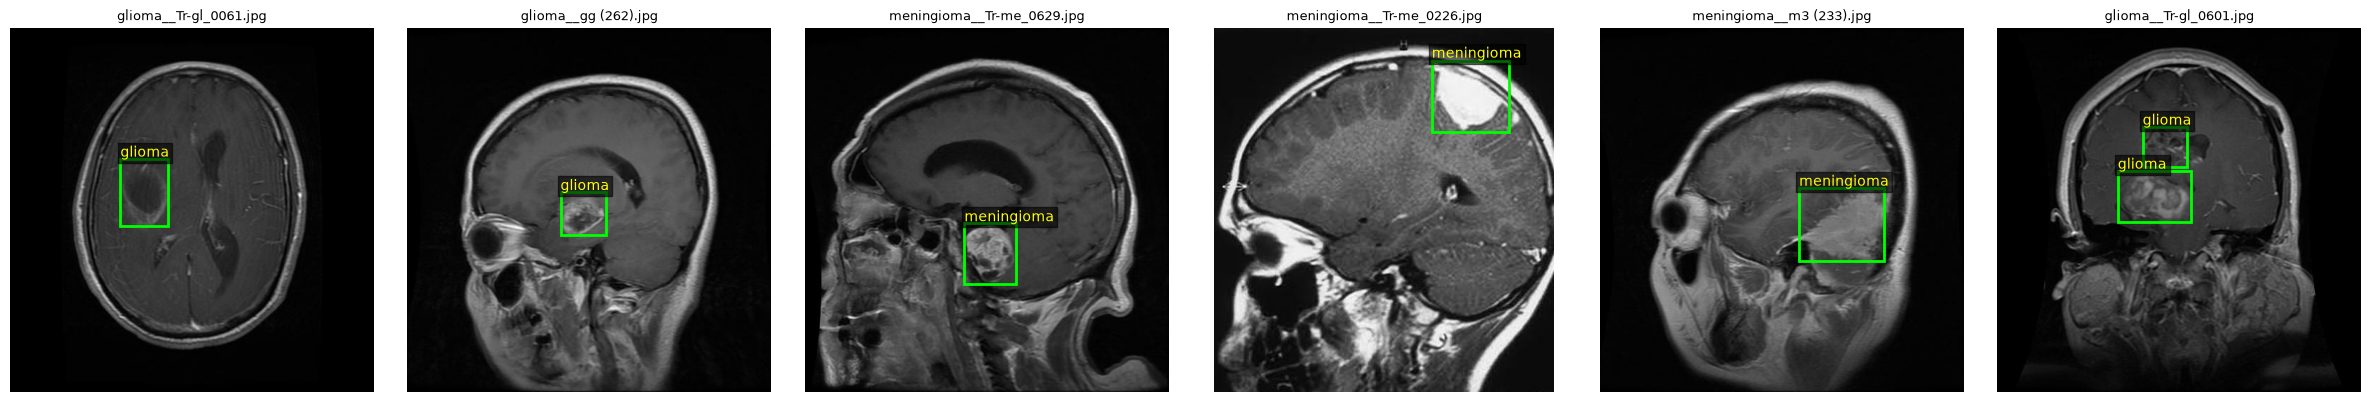

In [6]:
from src.detection.visualize import show_images
from src.detection.dataset import CLASS_NAMES

show_images(PROCESSED / "train" / "images",
            PROCESSED / "train" / "labels",
            class_names=CLASS_NAMES, n=6)

## Étape 6 — Vérifier le fichier `data.yaml`

`data.yaml` précise où se trouvent les trois ensembles et **quelles classes YOLO doit détecter**.

> Attention : `data.yaml` décrit le **dataset**. Les paramètres d'augmentation et d'entraînement se trouvent, eux, dans `configs/detection_train.yaml`.

In [7]:
print("===== data.yaml =====")
print(Path(data_yaml).read_text(encoding="utf-8"))
print("===== configuration d'entraînement =====")
print(CONFIG.read_text(encoding="utf-8"))

===== data.yaml =====
path: "C:/Users/errak/Desktop/BrainTumorDetectionAI/data/processed/detection"
train: train/images
val: val/images
test: test/images
nc: 3
names:
  0: glioma
  1: meningioma
  2: pituitary

===== configuration d'entraînement =====
# Configuration simple d'entraînement YOLOv8 (IRM cérébrales)
# Pour un GPU 24 Go : tu peux tester batch: 16 et imgsz: 640.
# Sur CPU, réduire imgsz à 416 pour démarrer.
model: yolov8n.pt         # YOLOv8 nano : léger pour commencer
epochs: 50               # Maximum de passages sur train
batch: 8                 # Nombre d'images par étape
imgsz: 512               # Taille des images carrées
optimizer: AdamW
lr0: 0.001               # Learning rate initial
patience: 15             # Early stopping si val ne s'améliore plus
seed: 42
workers: 0               # Simple et robuste sur Windows / Jupyter
plots: true
save: true

# Augmentations modérées : adaptées à des images médicales
# Ne pas créer de flips/montages irréalistes sans validatio

## Étape 7 — Entraîner YOLOv8

Nous partons de `yolov8n.pt`, un petit modèle **préentraîné**. L'appel `YOLO(...).train(...)` :

1. charge les poids préentraînés ;
2. redimensionne et prépare les images ;
3. réalise les augmentations **uniquement sur train** ;
4. prédit des boîtes et des classes ;
5. calcule les pertes de localisation et de classification ;
6. met à jour les poids avec l'optimiseur ;
7. contrôle les métriques sur `val` à la fin des époques ;
8. sauvegarde le modèle le plus performant dans `best.pt`.

Les hyperparamètres sont modifiables dans `configs/detection_train.yaml` : `epochs=50`, `batch=8`, `imgsz=512`, `lr0=0.001`, petites rotations et translation. Réduis `imgsz` si l'entraînement est trop lent, et augmente `batch` si ton GPU le permet.

**La cellule suivante lance un véritable entraînement** ; il faut les données et du temps de calcul.

In [8]:
from src.detection.train import train_yolov8

best_model = train_yolov8(
    data_yaml=data_yaml,
    config_path=CONFIG,
    project_dir=ARTIFACTS,
)

print("Modèle final retenu :", best_model)

Modèle préentraîné : yolov8n.pt
Appareil : cpu
New https://pypi.org/project/ultralytics/8.4.192 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.183  Python-3.12.10 torch-2.14.1+cpu CPU (12th Gen Intel Core i5-1235U)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\errak\Desktop\BrainTumorDetectionAI\data\processed\detection\data.yaml, degrees=5.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.05, imgsz=512, iou=0.7, kobj=1.0, line_width=No

c:\Users\errak\Desktop\BrainTumorDetectionAI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Overriding model.yaml nc=80 with nc=3

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytics

2026/10/29 09:23:18 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/29 09:23:18 INFO mlflow.store.db.utils: Updating database tables
2026/10/29 09:23:21 INFO mlflow.tracking.fluent: Experiment with name 'C:\Users\errak\Desktop\BrainTumorDetectionAI\artifacts\detection' does not exist. Creating a new experiment.


MLflow: logging run_id(ae61b455dcbe49d8b1ad8ee5a1e28e7b) to sqlite:///C:/Users/errak/Desktop/BrainTumorDetectionAI/notebooks/mlflow.db
MLflow: disable with 'yolo settings mlflow=False'
Using 2424 train, 480 val images for fraction=1.0 at imgsz=512
Using 0 dataloader workers
Logging results to C:\Users\errak\Desktop\BrainTumorDetectionAI\artifacts\detection\yolov8_brain_tumor
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       1/50         0G      1.299      3.846      1.407          7        512: 5% ╸─────────── 17/303 2.5s/it 47.4s<11:56


KeyboardInterrupt: 

## Étape 8 — Analyser les courbes d'entraînement

Ultralytics enregistre notamment `results.csv`, `results.png`, la matrice de confusion et les fichiers de poids.

- Une baisse des pertes avec une amélioration des métriques sur **val** est un bon signe.
- Une amélioration de **train** sans amélioration de **val** peut indiquer du surapprentissage.
- Le **test** ne doit pas servir à choisir les hyperparamètres.

In [ ]:
results_csv = ARTIFACTS / "yolov8_brain_tumor" / "results.csv"
training_history = pd.read_csv(results_csv)
training_history.columns = training_history.columns.str.strip()
display(training_history.tail())

map_columns = [c for c in training_history.columns if "mAP50" in c]
if map_columns:
    training_history.plot(x="epoch", y=map_columns, figsize=(8, 4), grid=True)
    plt.title("Évolution des métriques mAP sur validation")
    plt.show()

## Étape 9 — Évaluer sur le **test indépendant**

Le modèle `best.pt` est chargé puis testé sur des images **non utilisées pendant l'entraînement**.

- **Precision** : quelle proportion des détections est correcte ?
- **Recall** : quelle proportion des tumeurs annotées est retrouvée ?
- **mAP@0.5** : précision moyenne à IoU = 0,5.
- **mAP@0.5:0.95** : moyenne sur plusieurs seuils IoU ; elle exige des boîtes plus précises.

L'évaluation écrit `artifacts/detection/evaluation_test/metrics.json` et les graphiques disponibles.

In [ ]:
from src.detection.evaluate import evaluate_yolov8

metrics = evaluate_yolov8(
    model_path=best_model,
    data_yaml=data_yaml,
    project_dir=ARTIFACTS,
    split="test",
    imgsz=512,
    batch=8,
)
display(pd.DataFrame([metrics]))

## Étape 10 — Effectuer une prédiction sur une IRM du test

Choisis une image jamais utilisée dans `train`. Le modèle peut proposer zéro, une ou plusieurs boîtes.

Le fichier annoté est aussi enregistré dans `artifacts/detection/predictions/`. Pour une vraie évaluation indépendante, privilégier ultérieurement des IRM provenant de patients distincts.

In [ ]:
from src.detection.predict import predict_image

image_test = sorted((PROCESSED / "test" / "images").iterdir())[0]
print("Image de test :", image_test.name)

predictions = predict_image(
    model_path=best_model,
    image_path=image_test,
    output_dir=ARTIFACTS,
    confidence=0.25,
)

## Étape 11 — Retrouver et sauvegarder les artefacts

Le dossier d'entraînement contient automatiquement les poids `best.pt` (meilleur modèle) et `last.pt` (dernier état), les courbes, les paramètres utilisés (`args.yaml`) et les résultats d'entraînement (`results.csv`).

**À conserver pour ton projet :** le fichier `.pt`, le `data.yaml` (et l'ordre des classes), la configuration d'entraînement, le rapport de préparation et le rapport de test. Ne publie pas de données médicales contenant des informations personnelles.

In [ ]:
important_files = [
    best_model,
    ARTIFACTS / "yolov8_brain_tumor" / "weights" / "last.pt",
    ARTIFACTS / "yolov8_brain_tumor" / "results.csv",
    ARTIFACTS / "evaluation_test" / "metrics.json",
    data_yaml,
    report_csv,
    CONFIG,
]
for file_path in important_files:
    print(("✅" if Path(file_path).exists() else "❌"), file_path)

### Comment vérifier la généralisation ?

- Contrôler les **faux négatifs** : une tumeur peut-elle être manquée ?
- Consulter la matrice de confusion, les courbes Precision-Recall et la mAP par classe.
- Examiner plusieurs prédictions de `test` ; comparer les boîtes prédites aux annotations.
- Vérifier qu'aucun même patient, examen proche ou image augmentée n'est partagé entre `train`, `val` et `test`.

Un résultat satisfaisant sur ce dataset reste une **expérience de machine learning**, pas une validation clinique.

Documentation officielle : https://docs.ultralytics.com/datasets/detect/ — https://docs.ultralytics.com/modes/train/